In [ ]:

# STEP 1: CONNECT GOOGLE DRIVE AND FIND THE DATASET

from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:
import os

folder_path = "/content/drive/MyDrive/Infosys Project/archive/2020-05-01"

In [ ]:

# STEP 2: LOAD THE DATASET FROM THE FOUND PATH

import pandas as pd
import os

# Construct the file path directly using the defined folder_path
csv_path = os.path.join(folder_path, "ted_talks_en.csv")

if not os.path.exists(csv_path):
    raise FileNotFoundError(
        f"Could not find 'ted_talks_en.csv' at: {csv_path}. Please check your Google Drive path."
    )

# Load the dataset
df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("File path:", csv_path)
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
File path: /content/drive/MyDrive/Infosys Project/archive/2020-05-01/ted_talks_en.csv
Dataset shape: (4005, 19)


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


In [ ]:

# MILESTONE 2 — STEP 3: FEATURE ENGINEERING

import pandas as pd
import numpy as np
import ast

# Check that the dataset is loaded
if "df" not in globals():
    raise ValueError("Please complete the dataset-loading step first.")

# Check required columns
required_columns = [
    "talk_id", "title", "topics", "description", "transcript"
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Create a working copy without changing the original dataset
talks_df = df[required_columns].copy()

# Convert topics into readable text
def topics_to_text(value):
    if isinstance(value, (list, tuple, set)):
        return " ".join(str(item) for item in value)

    if not isinstance(value, str) or not value.strip():
        return ""

    # Handle topics stored as strings representing lists
    try:
        parsed = ast.literal_eval(value)
        if isinstance(parsed, (list, tuple, set)):
            return " ".join(str(item) for item in parsed)
    except (ValueError, SyntaxError):
        pass

    return value

# Handle missing text values in the working copy only
talks_df["title"] = talks_df["title"].fillna("").astype(str)
talks_df["topics_text"] = talks_df["topics"].apply(topics_to_text)
talks_df["description"] = talks_df["description"].fillna("").astype(str)
talks_df["transcript"] = talks_df["transcript"].fillna("").astype(str)

# Combine text fields; give titles and topics extra emphasis
talks_df["combined_text"] = (
    talks_df["title"] + " " +
    talks_df["title"] + " " +
    talks_df["topics_text"] + " " +
    talks_df["topics_text"] + " " +
    talks_df["description"] + " " +
    talks_df["transcript"]
).str.strip()

# Display the results
print("Feature engineering completed successfully!")
print("Number of talks:", len(talks_df))
print("Empty combined-text records:", (talks_df["combined_text"] == "").sum())

display(
    talks_df[["talk_id", "title", "topics_text", "combined_text"]].head(3)
)


Feature engineering completed successfully!
Number of talks: 4005
Empty combined-text records: 0


,talk_id,title,topics_text,combined_text
0,1,Averting the climate crisis,alternative energy cars climate change culture...,Averting the climate crisis Averting the clima...
1,92,The best stats you've ever seen,Africa Asia Google demo economics global issue...,The best stats you've ever seen The best stats...
2,7,Simplicity sells,computers entertainment interface design media...,Simplicity sells Simplicity sells computers en...


In [ ]:

#STEP 4: TF-IDF VECTORIZATION

import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

# Check that feature engineering has been completed
if "talks_df" not in globals() or "combined_text" not in talks_df.columns:
    raise ValueError("Please run Step 3: Feature Engineering first.")

# Configure the TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",  # Ignore common English words
    max_features=20000,    # Keep up to 20,000 vocabulary features
    ngram_range=(1, 2),    # Use single words and two-word phrases
    min_df=2,              # Ignore terms appearing in fewer than 2 talks
    max_df=0.95,            # Ignore terms appearing in over 95% of talks
    dtype=np.float32        # Use less memory
)

# Convert combined text into a sparse numerical matrix
tfidf_matrix = tfidf_vectorizer.fit_transform(
    talks_df["combined_text"]
)

# Inspect the results
feature_names = tfidf_vectorizer.get_feature_names_out()

print("TF-IDF vectorization completed successfully!")
print("Number of talks:", tfidf_matrix.shape[0])
print("Number of vocabulary features:", tfidf_matrix.shape[1])
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Non-zero values:", tfidf_matrix.nnz)
print("Matrix format:", tfidf_matrix.getformat())

print("\nFirst 30 vocabulary terms:")
print(feature_names[:30].tolist())


TF-IDF vectorization completed successfully!
Number of talks: 4005
Number of vocabulary features: 20000
TF-IDF matrix shape: (4005, 20000)
Non-zero values: 1931308
Matrix format: csr

First 30 vocabulary terms:
['00', '000', '000 000', '000 children', '000 days', '000 different', '000 dollars', '000 employees', '000 feet', '000 genes', '000 hours', '000 kilometers', '000 meters', '000 miles', '000 people', '000 pounds', '000 species', '000 square', '000 students', '000 times', '000 tons', '000 women', '000 year', '000 years', '10', '10 000', '10 11', '10 15', '10 20', '10 billion']


In [ ]:

# STEP 5: COSINE SIMILARITY & RECOMMENDATIONS

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Check that TF-IDF vectorization is complete
if "tfidf_matrix" not in globals():
    raise ValueError("Please run Step 4: TF-IDF Vectorization first.")

# Function to recommend similar TED Talks
def recommend_talks(talk_title, top_n=5):

    # Find the selected talk by title (case-insensitive)
    matches = talks_df.index[
        talks_df["title"].str.strip().str.casefold()
        == talk_title.strip().casefold()
    ].tolist()

    if not matches:
        print("Talk title not found:", talk_title)
        print("\nHere are some available titles:")
        display(talks_df[["title"]].head(10))
        return None

    # Select the first matching talk
    talk_index = matches[0]

    # Compare this talk with every talk using cosine similarity
    similarity_scores = cosine_similarity(
        tfidf_matrix[talk_index],
        tfidf_matrix
    ).ravel()

    # Exclude the selected talk from its own recommendations
    similarity_scores[talk_index] = -1

    # Find the top N most similar talks
    top_indices = np.argsort(similarity_scores)[::-1][:top_n]

    # Prepare the recommendation results
    recommendations = talks_df.iloc[top_indices][
        ["talk_id", "title", "topics_text"]
    ].copy()

    recommendations["similarity_score"] = similarity_scores[top_indices]

    print("Selected TED Talk:", talks_df.iloc[talk_index]["title"])
    print(f"\nTop {top_n} similar TED Talks:")

    return recommendations.reset_index(drop=True)


# Try a sample recommendation
recommendations = recommend_talks(
    "Do schools kill creativity?",
    top_n=5
)

if recommendations is not None:
    display(recommendations)


Selected TED Talk: Do schools kill creativity?

Top 5 similar TED Talks:


,talk_id,title,topics_text,similarity_score
0,865,Bring on the learning revolution!,children creativity education invention,0.374284
1,1738,How to escape education's death valley,culture education teaching student,0.368283
2,87,Nerdcore comedy,collaboration comedy community culture dance d...,0.285235
3,2182,How to run a company with (almost) no rules,business creativity philosophy work leadership,0.270325
4,949,The child-driven education,children education technology web global devel...,0.269903


Talk: Averting the climate crisis


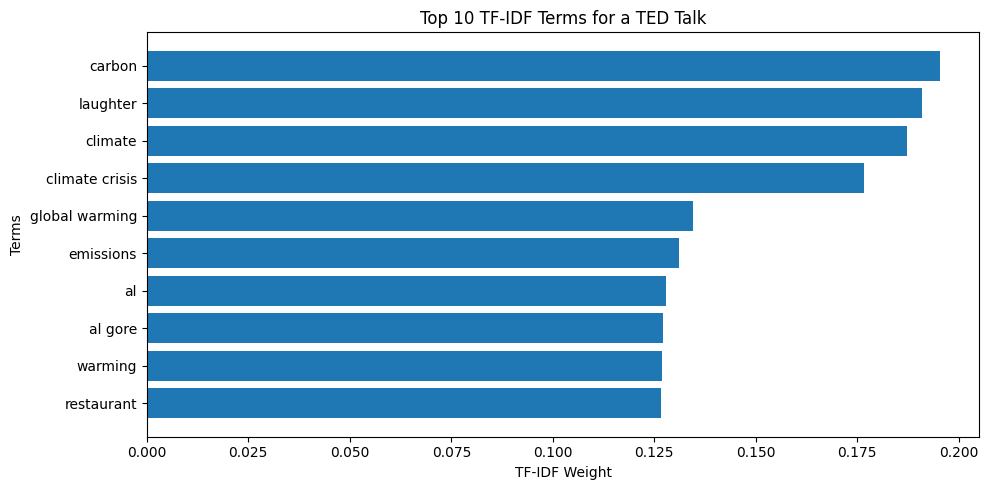

In [ ]:

# STEP 6A: TOP TF-IDF TERMS

import numpy as np
import matplotlib.pyplot as plt

# Choose a talk to analyze
talk_index = 0

# Get the TF-IDF vector for this talk
talk_vector = tfidf_matrix[talk_index]

# Find the indices of non-zero TF-IDF values
nonzero_indices = talk_vector.indices
nonzero_values = talk_vector.data

# Select the 10 terms with the highest weights
top_positions = np.argsort(nonzero_values)[-10:][::-1]

top_terms = [
    tfidf_vectorizer.get_feature_names_out()[nonzero_indices[i]]
    for i in top_positions
]
top_weights = nonzero_values[top_positions]

# Display the talk title
print("Talk:", talks_df.iloc[talk_index]["title"])

# Plot the terms
plt.figure(figsize=(10, 5))
plt.barh(top_terms[::-1], top_weights[::-1])
plt.xlabel("TF-IDF Weight")
plt.ylabel("Terms")
plt.title("Top 10 TF-IDF Terms for a TED Talk")
plt.tight_layout()
plt.show()


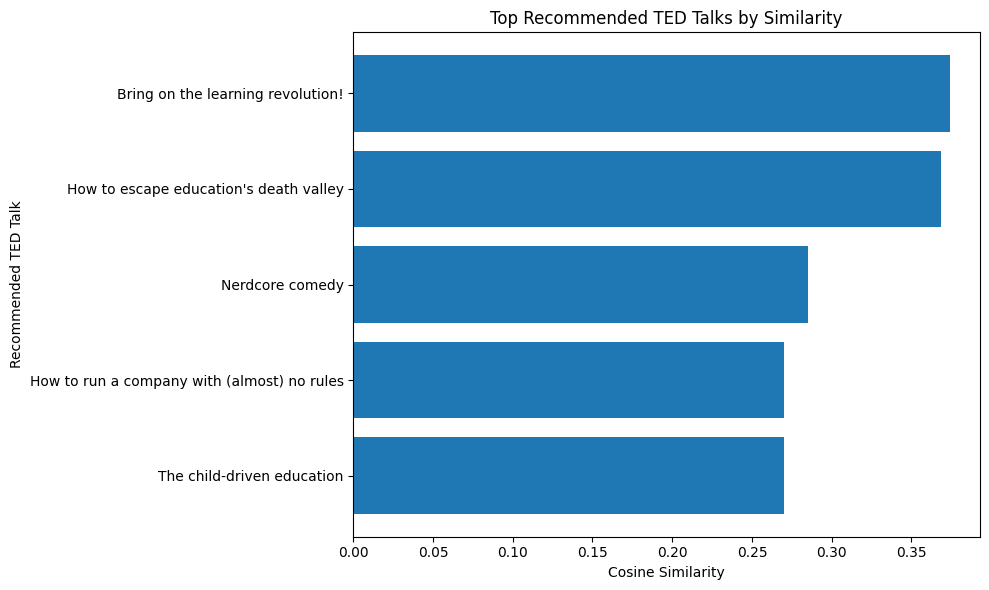

In [ ]:

# STEP 6B: RECOMMENDATION SIMILARITY GRAPH

if "recommendations" not in globals() or recommendations is None:
    raise ValueError("Run Step 5 and generate recommendations first.")

plot_df = recommendations.sort_values("similarity_score")

plt.figure(figsize=(10, 6))
plt.barh(
    plot_df["title"],
    plot_df["similarity_score"]
)
plt.xlabel("Cosine Similarity")
plt.ylabel("Recommended TED Talk")
plt.title("Top Recommended TED Talks by Similarity")
plt.tight_layout()
plt.show()


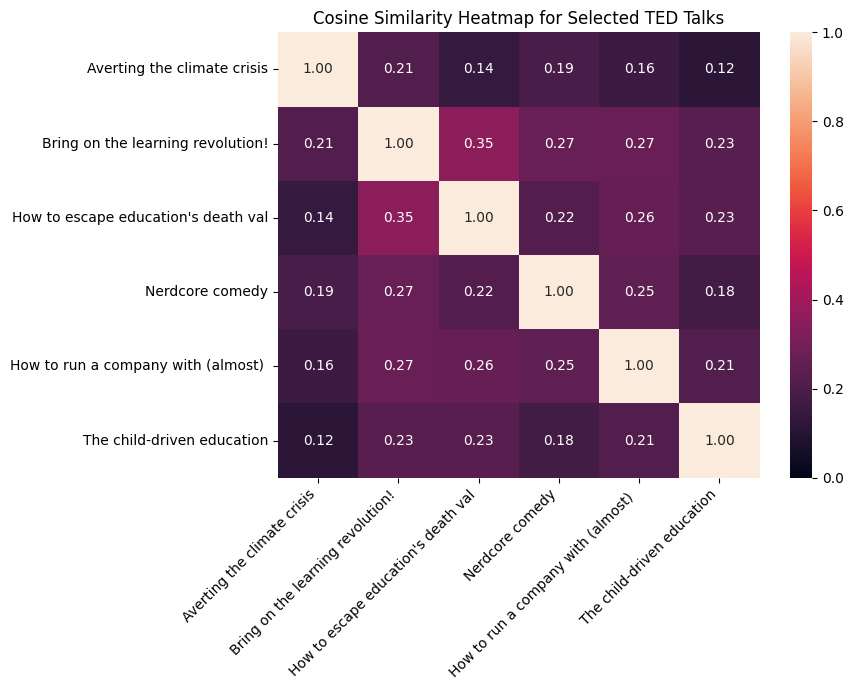

In [ ]:

# STEP 6C: SIMILARITY HEATMAP

import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

# Use the selected talk and its recommendations
selected_index = 0
sample_indices = [selected_index]

if "recommendations" in globals() and recommendations is not None:
    for talk_id in recommendations["talk_id"]:
        matches = talks_df.index[talks_df["talk_id"] == talk_id].tolist()
        if matches and matches[0] not in sample_indices:
            sample_indices.append(matches[0])

sample_indices = sample_indices[:6]

# Calculate similarities only for this small sample
sample_matrix = tfidf_matrix[sample_indices]
sample_similarity = cosine_similarity(sample_matrix)

sample_titles = [
    talks_df.iloc[i]["title"][:35]
    for i in sample_indices
]

plt.figure(figsize=(9, 7))
sns.heatmap(
    sample_similarity,
    annot=True,
    fmt=".2f",
    xticklabels=sample_titles,
    yticklabels=sample_titles,
    vmin=0,
    vmax=1
)
plt.title("Cosine Similarity Heatmap for Selected TED Talks")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

#STEP 7: SAVE MODELS AND OUTPUTS

import os
import json
import joblib
import pandas as pd
from scipy.sparse import save_npz

# Create an output folder in Google Colab
OUTPUT_DIR = "/content/milestone2_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Save the fitted TF-IDF vectorizer
joblib.dump(
    tfidf_vectorizer,
    os.path.join(OUTPUT_DIR, "tfidf_vectorizer.joblib")
)

# 2. Save the sparse TF-IDF matrix
save_npz(
    os.path.join(OUTPUT_DIR, "tfidf_matrix.npz"),
    tfidf_matrix
)

# 3. Save talk metadata in the same row order as the matrix
metadata = talks_df[
    ["talk_id", "title", "topics_text"]
].copy()

metadata.to_csv(
    os.path.join(OUTPUT_DIR, "talk_metadata.csv"),
    index=False
)

# 4. Save the recommendations generated in Step 5
if "recommendations" in globals() and recommendations is not None:
    recommendations.to_csv(
        os.path.join(OUTPUT_DIR, "top_similar_talks.csv"),
        index=False
    )

# 5. Save the vectorizer configuration
config = {
    "method": "TF-IDF",
    "stop_words": "english",
    "max_features": 20000,
    "ngram_range": [1, 2],
    "min_df": 2,
    "max_df": 0.95,
    "dtype": "float32",
    "similarity_method": "cosine_similarity"
}

with open(
    os.path.join(OUTPUT_DIR, "vectorization_config.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(config, file, indent=4)

# Display saved files
print(" The outputs saved successfully!\n")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    filepath = os.path.join(OUTPUT_DIR, filename)
    print(f"{filename} — {os.path.getsize(filepath) / 1024:.2f} KB")


 The outputs saved successfully!

talk_metadata.csv — 472.71 KB
tfidf_matrix.npz — 10015.42 KB
tfidf_vectorizer.joblib — 679.99 KB
top_similar_talks.csv — 0.54 KB
vectorization_config.json — 0.23 KB


In [ ]:

#STEP 7B: PACKAGE OUTPUTS FOR DOWNLOAD

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/milestone2_outputs",
    "zip",
    OUTPUT_DIR
)

print("ZIP file created:", zip_path)

files.download(zip_path)


ZIP file created: /content/milestone2_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# MODULE 4: STEP 1 — LOAD SAVED ARTIFACTS

import os
import joblib
import pandas as pd
import numpy as np

from scipy.sparse import load_npz
from sklearn.metrics.pairwise import cosine_similarity

# Folder where Module 3 outputs were saved
OUTPUT_DIR = "/content/milestone2_outputs"

# Check whether the saved files exist
required_files = [
    "tfidf_vectorizer.joblib",
    "tfidf_matrix.npz",
    "talk_metadata.csv"
]

missing_files = [
    file for file in required_files
    if not os.path.exists(os.path.join(OUTPUT_DIR, file))
]

if missing_files:
    print("Missing files:", missing_files)
    print("Please locate your saved Module 3 outputs or rerun its saving cell.")
else:
    # Load the trained TF-IDF vectorizer
    tfidf_vectorizer = joblib.load(
        os.path.join(OUTPUT_DIR, "tfidf_vectorizer.joblib")
    )

    # Load numerical vectors of all TED Talks
    tfidf_matrix = load_npz(
        os.path.join(OUTPUT_DIR, "tfidf_matrix.npz")
    )

    # Load talk IDs, titles, and topics
    talk_metadata = pd.read_csv(
        os.path.join(OUTPUT_DIR, "talk_metadata.csv")
    )

    print("Module 3 artifacts loaded successfully!")
    print("Number of talks:", len(talk_metadata))
    print("TF-IDF matrix shape:", tfidf_matrix.shape)
    print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))

    display(talk_metadata.head())

Module 3 artifacts loaded successfully!
Number of talks: 4005
TF-IDF matrix shape: (4005, 20000)
Vocabulary size: 20000


,talk_id,title,topics_text
0,1,Averting the climate crisis,alternative energy cars climate change culture...
1,92,The best stats you've ever seen,Africa Asia Google demo economics global issue...
2,7,Simplicity sells,computers entertainment interface design media...
3,53,Greening the ghetto,MacArthur grant activism business cities envir...
4,66,Do schools kill creativity?,children creativity culture dance education pa...


In [ ]:
# MODULE 4: STEP 2 — VALIDATE LOADED DATA

assert tfidf_matrix.shape[0] == len(talk_metadata), (
    "Mismatch between talk metadata and TF-IDF vectors!"
)

assert "title" in talk_metadata.columns, (
    "The title column is missing!"
)

print("Validation successful!")
print("Metadata rows:", len(talk_metadata))
print("Vector rows:", tfidf_matrix.shape[0])
print("Vector features:", tfidf_matrix.shape[1])
print("Missing titles:", talk_metadata["title"].isna().sum())
print("Duplicate talk titles:", talk_metadata["title"].duplicated().sum())

Validation successful!
Metadata rows: 4005
Vector rows: 4005
Vector features: 20000
Missing titles: 0
Duplicate talk titles: 0


In [ ]:
# MODULE 4: STEP 3 — CONTENT-BASED RECOMMENDATION ENGINE

from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

def recommend_talks(talk_title, top_n=5):

    # Find the talk using its title (case-insensitive)
    matches = talk_metadata.index[
        talk_metadata["title"].fillna("").str.strip().str.casefold()
        == talk_title.strip().casefold()
    ].tolist()

    if not matches:
        print("Talk not found. Please choose a title from the dataset.")
        display(talk_metadata[["talk_id", "title"]].head(10))
        return None

    # Select the first exact title match
    talk_index = matches[0]

    # Compare this talk with all other talks
    similarity_scores = cosine_similarity(
        tfidf_matrix[talk_index],
        tfidf_matrix
    ).ravel()

    # Exclude the selected talk from its own recommendations
    similarity_scores[talk_index] = -1

    # Get the top similar talks
    top_indices = np.argsort(similarity_scores)[::-1][:top_n]

    # Prepare recommendation results
    results = talk_metadata.iloc[top_indices].copy()
    results["similarity_score"] = similarity_scores[top_indices]

    return results.reset_index(drop=True)


# Test the recommendation engine
recommendations = recommend_talks(
    "Do schools kill creativity?",
    top_n=5
)

if recommendations is not None:
    display(recommendations)

,talk_id,title,topics_text,similarity_score
0,865,Bring on the learning revolution!,children creativity education invention,0.374284
1,1738,How to escape education's death valley,culture education teaching student,0.368283
2,87,Nerdcore comedy,collaboration comedy community culture dance d...,0.285235
3,2182,How to run a company with (almost) no rules,business creativity philosophy work leadership,0.270325
4,949,The child-driven education,children education technology web global devel...,0.269903


In [ ]:
# MODULE 4: STEP 4 — BASIC RECOMMENDATION EVALUATION

if recommendations is not None and len(recommendations) > 0:

    # Check whether recommendations were returned
    print("Number of recommendations:", len(recommendations))

    # Check for duplicate recommended titles
    print(
        "Duplicate recommendations:",
        recommendations["title"].duplicated().sum()
    )

    # Summarize similarity scores
    print(
        "Average similarity score:",
        round(recommendations["similarity_score"].mean(), 4)
    )

    print(
        "Highest similarity score:",
        round(recommendations["similarity_score"].max(), 4)
    )

    print(
        "Lowest similarity score:",
        round(recommendations["similarity_score"].min(), 4)
    )

    # Display the final recommendations
    display(
        recommendations[
            ["talk_id", "title", "similarity_score"]
        ]
    )

else:
    print("Run a successful recommendation query before evaluation.")

Number of recommendations: 5
Duplicate recommendations: 0
Average similarity score: 0.3136
Highest similarity score: 0.3743
Lowest similarity score: 0.2699


,talk_id,title,similarity_score
0,865,Bring on the learning revolution!,0.374284
1,1738,How to escape education's death valley,0.368283
2,87,Nerdcore comedy,0.285235
3,2182,How to run a company with (almost) no rules,0.270325
4,949,The child-driven education,0.269903


In [ ]:
# MODULE 4: STEP 5 — SAVE MODEL AND OUTPUTS

import os
import json
import joblib
from scipy.sparse import save_npz

# Create a folder for Module 4 outputs
MODEL_DIR = "/content/module4_outputs"
os.makedirs(MODEL_DIR, exist_ok=True)

# 1. Save the fitted TF-IDF vectorizer
joblib.dump(
    tfidf_vectorizer,
    os.path.join(MODEL_DIR, "tfidf_vectorizer.joblib")
)

# 2. Save the TF-IDF matrix
save_npz(
    os.path.join(MODEL_DIR, "tfidf_matrix.npz"),
    tfidf_matrix
)

# 3. Save talk metadata
talk_metadata.to_csv(
    os.path.join(MODEL_DIR, "talk_metadata.csv"),
    index=False
)

# 4. Save model configuration
config = {
    "recommendation_strategy": "Content-based filtering",
    "text_representation": "TF-IDF",
    "similarity_measure": "Cosine similarity",
    "max_features": 20000,
    "ngram_range": [1, 2],
    "min_df": 2,
    "max_df": 0.95,
    "stop_words": "english",
    "dtype": "float32",
    "default_top_n": 5,
    "number_of_talks": int(tfidf_matrix.shape[0]),
    "number_of_features": int(tfidf_matrix.shape[1])
}

with open(
    os.path.join(MODEL_DIR, "model_config.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(config, file, indent=4)

# 5. Save example recommendations, if available
if recommendations is not None:
    recommendations.to_csv(
        os.path.join(MODEL_DIR, "example_recommendations.csv"),
        index=False
    )

# 6. Display saved files
print("Saved Module 4 artifacts:")
for filename in sorted(os.listdir(MODEL_DIR)):
    print("-", filename)

print("\nModel configuration:")
print(json.dumps(config, indent=2))

Saved Module 4 artifacts:
- example_recommendations.csv
- model_config.json
- talk_metadata.csv
- tfidf_matrix.npz
- tfidf_vectorizer.joblib

Model configuration:
{
  "recommendation_strategy": "Content-based filtering",
  "text_representation": "TF-IDF",
  "similarity_measure": "Cosine similarity",
  "max_features": 20000,
  "ngram_range": [
    1,
    2
  ],
  "min_df": 2,
  "max_df": 0.95,
  "stop_words": "english",
  "dtype": "float32",
  "default_top_n": 5,
  "number_of_talks": 4005,
  "number_of_features": 20000
}


In [ ]:
# MODULE 4: STEP 6 — CREATE AND DOWNLOAD ZIP

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/module4_outputs",
    "zip",
    MODEL_DIR
)

print("ZIP archive created successfully!")
files.download(zip_path)

ZIP archive created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# MODULE 4 — TEST THE RECOMMENDATION ENGINE

talk_title = input("Enter a TED Talk title: ")

results = recommend_talks(talk_title, top_n=5)

if results is not None:
    print("\nRecommended TED Talks:")
    display(
        results[
            ["talk_id", "title", "similarity_score"]
        ]
    )

Enter a TED Talk title: Do schools kill creativity?

Recommended TED Talks:


,talk_id,title,similarity_score
0,865,Bring on the learning revolution!,0.374284
1,1738,How to escape education's death valley,0.368283
2,87,Nerdcore comedy,0.285235
3,2182,How to run a company with (almost) no rules,0.270325
4,949,The child-driven education,0.269903


In [ ]:
# TEST MULTIPLE EXAMPLES

test_titles = talk_metadata["title"].dropna().head(3).tolist()

for title in test_titles:
    print("\n" + "=" * 60)
    print("Input Talk:", title)

    results = recommend_talks(title, top_n=5)

    if results is not None:
        display(results[["title", "similarity_score"]])


Input Talk: Averting the climate crisis


,title,similarity_score
0,New thinking on the climate crisis,0.337124
1,How we can turn the tide on climate,0.304859
2,The disarming case to act right now on climate...,0.283225
3,A climate solution where all sides can win,0.283101
4,The case for optimism on climate change,0.282981



Input Talk: The best stats you've ever seen


,title,similarity_score
0,Let my dataset change your mindset,0.562367
1,New insights on poverty,0.425581
2,The good news of the decade? We're winning the...,0.346219
3,Religions and babies,0.323843
4,"Global population growth, box by box",0.313869



Input Talk: Simplicity sells


,title,similarity_score
0,Nerdcore comedy,0.277345
1,Cool tricks your phone can do,0.270582
2,Designing for simplicity,0.269798
3,Design and discovery,0.263643
4,6 ways to save the internet,0.248283
